DATASET
   Study_Hours  Screen_Hours
0     5.745071      5.133407
1     4.792604      6.548291
2     5.971533      5.844332
3     7.284545      4.623224
4     4.648770      6.849271

COVARIANCE MATRIX
              Study_Hours  Screen_Hours
Study_Hours      1.855732     -1.348011
Screen_Hours    -1.348011      1.550437

CORRELATION MATRIX
              Study_Hours  Screen_Hours
Study_Hours       1.00000      -0.79471
Screen_Hours     -0.79471       1.00000

EIGENVALUES
[3.05971117 0.34645859]

EIGENVECTORS
[[-0.74582835 -0.66613818]
 [ 0.66613818 -0.74582835]]

EXPLAINED VARIANCE RATIO
[0.89828499 0.10171501]

CUMULATIVE EXPLAINED VARIANCE
[0.89828499 1.        ]


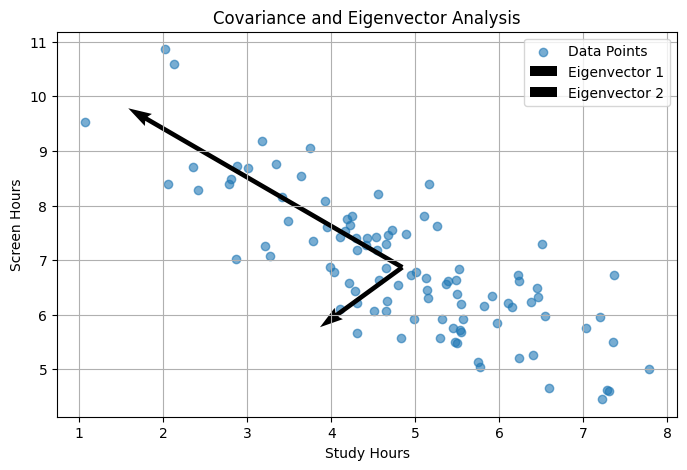

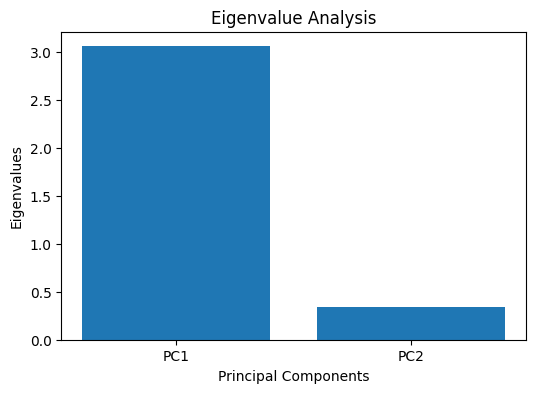

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

# 1. Generate dataset
study_hours = np.random.normal(5, 1.5, 100)

screen_hours = (
    10 - 0.65 * study_hours
    + np.random.normal(0, 0.8, 100)
)

data = pd.DataFrame({
    "Study_Hours": study_hours,
    "Screen_Hours": screen_hours
})

print("DATASET")
print(data.head())

# 2. Calculate covariance
covariance = data.cov()

print("\nCOVARIANCE MATRIX")
print(covariance)

# 3. Calculate correlation
correlation = data.corr()

print("\nCORRELATION MATRIX")
print(correlation)

# 4. Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(
    covariance.to_numpy()
)

# Arrange in descending order
indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

print("\nEIGENVALUES")
print(eigenvalues)

print("\nEIGENVECTORS")
print(eigenvectors)

# 5. Explained variance
explained_variance = (
    eigenvalues / np.sum(eigenvalues)
)

print("\nEXPLAINED VARIANCE RATIO")
print(explained_variance)

print("\nCUMULATIVE EXPLAINED VARIANCE")
print(np.cumsum(explained_variance))

# 6. Plot dataset
X = data.to_numpy()
mean = X.mean(axis=0)

plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    alpha=0.6,
    label="Data Points"
)

# Plot eigenvectors
for i in range(2):
    direction = (
        eigenvectors[:, i]
        * np.sqrt(eigenvalues[i]) * 2.5
    )

    plt.quiver(
        mean[0], mean[1],
        direction[0], direction[1],
        angles="xy",
        scale_units="xy",
        scale=1,
        label=f"Eigenvector {i+1}"
    )

plt.xlabel("Study Hours")
plt.ylabel("Screen Hours")
plt.title("Covariance and Eigenvector Analysis")
plt.legend()
plt.grid()
plt.show()

# 7. Eigenvalue visualization
plt.figure(figsize=(6, 4))

plt.bar(
    ["PC1", "PC2"],
    eigenvalues
)

plt.xlabel("Principal Components")
plt.ylabel("Eigenvalues")
plt.title("Eigenvalue Analysis")

plt.show()